# Proyecto final: calidad de vida en Europa (2015-2023)
### Técnicas de Recogida de Datos · Entregable 3

**Fuente de datos:** API pública del Banco Mundial (*World Bank Indicators API v2*)

**Idea de negocio:** un **comparador de países** para personas que quieren mudarse a trabajar a otro país de Europa. La herramienta reúne en un solo dataframe indicadores de economía, coste de vida, salud, seguridad, medio ambiente y sociedad de **31 países** (UE-27 más Noruega, Suiza, Islandia y Reino Unido) entre **2015 y 2023**.

El notebook sirve a la vez de código y de **informe**. Cuenta cada paso, los errores que aparecieron por el camino y cómo se resolvieron. Para reproducirlo basta con *Run All* y conexión a Internet.

## Índice
1. Elección de la fuente
2. Configuración
3. Primer contacto con la API (y primeros errores)
4. Función de descarga robusta
5. Descarga de los indicadores y de los metadatos de país
6. Construcción del dataframe
7. Calidad de los datos: valores nulos e imputación
8. El dataframe final
9. Aplicación: índice de calidad de vida y comparador de países
10. Resumen de errores y soluciones
11. Conclusiones

## 1. Elección de la fuente

El enunciado pide una fuente externa **no vista en clase** (INE, Google Trends, Azure Maps, Facebook, YouTube, Amazon, Twitter, smartwatch, imágenes y web scraping quedan fuera) y, si es una API, **sin usar tiers de pago**.

La **API del Banco Mundial** cumple todo:

| Requisito | Banco Mundial |
|---|---|
| No vista en clase | ✔ |
| No es web scraping | ✔ Es una API REST documentada que devuelve JSON |
| Gratuita | ✔ No tiene planes de pago ni necesita clave (*API key*) |
| Datos útiles para la idea de negocio | ✔ Más de 1.400 indicadores por país y año |

Documentación: <https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api-documentation>

El formato de una petición es:

```
https://api.worldbank.org/v2/country/{códigos ISO3 separados por ;}/indicator/{código del indicador}?format=json&date=2015:2023
```

**Por qué no usar `wbgapi` o `pandas-datareader`.** Existen librerías que envuelven esta API, pero el objetivo de la asignatura es *recoger* los datos. Por eso las peticiones se hacen a mano con `requests`, y así se ven (y se resuelven) los problemas reales de trabajar con una API.

## 2. Configuración

Librerías, países, periodo e indicadores. Los indicadores se eligieron pensando en lo que mira alguien que se plantea mudarse. Para cada uno se guarda un nombre corto de columna, su dimensión y su **sentido**: `+1` si un valor alto es bueno y `-1` si un valor alto es malo. El sentido se usará después para construir el índice.

In [1]:
# Si falta alguna librería: %pip install requests pandas numpy matplotlib truststore
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
URL_BASE = "https://api.worldbank.org/v2"
ANIO_INICIO, ANIO_FIN = 2015, 2023

# UE-27 + Noruega, Suiza, Islandia y Reino Unido (código ISO3 -> nombre en español)
PAISES = {
    "AUT": "Austria", "BEL": "Bélgica", "BGR": "Bulgaria", "HRV": "Croacia",
    "CYP": "Chipre", "CZE": "Chequia", "DNK": "Dinamarca", "EST": "Estonia",
    "FIN": "Finlandia", "FRA": "Francia", "DEU": "Alemania", "GRC": "Grecia",
    "HUN": "Hungría", "IRL": "Irlanda", "ITA": "Italia", "LVA": "Letonia",
    "LTU": "Lituania", "LUX": "Luxemburgo", "MLT": "Malta", "NLD": "Países Bajos",
    "POL": "Polonia", "PRT": "Portugal", "ROU": "Rumanía", "SVK": "Eslovaquia",
    "SVN": "Eslovenia", "ESP": "España", "SWE": "Suecia",
    "NOR": "Noruega", "CHE": "Suiza", "ISL": "Islandia", "GBR": "Reino Unido",
}

# código Banco Mundial -> (columna, dimensión, sentido para el índice)
# sentido: +1 = más es mejor, -1 = más es peor, 0 = no entra en el índice
INDICADORES = {
    "NY.GDP.PCAP.PP.CD": ("pib_pc_ppa",          "Economía",       +1),
    "SL.UEM.TOTL.ZS":    ("desempleo",           "Economía",       -1),
    "SL.UEM.1524.ZS":    ("desempleo_juvenil",   "Economía",        0),
    "FP.CPI.TOTL.ZG":    ("inflacion",           "Economía",        0),
    "PA.NUS.PRVT.PP":    ("ppa_consumo",         "Coste de vida",   0),  # auxiliar
    "PA.NUS.FCRF":       ("tipo_cambio",         "Coste de vida",   0),  # auxiliar
    "SP.DYN.LE00.IN":    ("esperanza_vida",      "Salud",          +1),
    "SH.XPD.CHEX.PC.CD": ("gasto_sanitario_pc",  "Salud",          +1),
    "VC.IHR.PSRC.P5":    ("homicidios",          "Seguridad",      -1),
    "EN.ATM.PM25.MC.M3": ("pm25",                "Medio ambiente", -1),
    "SI.POV.GINI":       ("gini",                "Sociedad",       -1),
    "IT.NET.USER.ZS":    ("internet",            "Sociedad",       +1),
    "SP.POP.TOTL":       ("poblacion",           "Contexto",        0),
}

print(f"{len(PAISES)} países x {ANIO_FIN - ANIO_INICIO + 1} años = "
      f"{len(PAISES) * (ANIO_FIN - ANIO_INICIO + 1)} filas esperadas por indicador")
print(f"{len(INDICADORES)} indicadores")

31 países x 9 años = 279 filas esperadas por indicador
13 indicadores


## 3. Primer contacto con la API (y primeros errores)

Antes de descargar nada en bloque, se hace **una sola petición** de prueba (esperanza de vida de España en 2022) para ver qué devuelve la API.

### Error 1: `SSLCertVerificationError`

En el equipo donde se desarrolló el proyecto, la primera petición falló con:

```
requests.exceptions.SSLError: HTTPSConnectionPool(host='api.worldbank.org', port=443): Max retries exceeded ...
(Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed:
unable to get local issuer certificate (_ssl.c:1006)')))
```

**Diagnóstico.** La misma URL abría sin problema en el navegador y con `curl`. Así que el fallo no era de la API sino de Python. `requests` no usa los certificados de Windows: usa su propia lista (`certifi`). Si en el equipo hay un antivirus o un proxy que inspecciona el tráfico HTTPS, el certificado que llega está firmado por una autoridad que solo conoce Windows, y `certifi` lo rechaza.

**Soluciones posibles.**
- `verify=False`: funciona, pero **desactiva la seguridad** de la conexión. Descartada.
- Librería **`truststore`**: hace que Python use el almacén de certificados del sistema operativo. Es la solución correcta.

La celda intenta primero la conexión normal y solo recurre a `truststore` si falla. Así el notebook funciona en cualquier equipo, tenga o no este problema.

In [3]:
url_prueba = f"{URL_BASE}/country/ESP/indicator/SP.DYN.LE00.IN"
params_prueba = {"format": "json", "date": "2022"}

try:
    respuesta = requests.get(url_prueba, params=params_prueba, timeout=30)
    print("Conexión directa correcta: este equipo no necesita truststore.")
except requests.exceptions.SSLError as error:
    print("ERROR SSL con la configuración por defecto:")
    print("   ", str(error)[:230], "...\n")
    import truststore                      # %pip install truststore
    truststore.inject_into_ssl()           # usar los certificados del sistema operativo
    respuesta = requests.get(url_prueba, params=params_prueba, timeout=30)
    print("Con truststore la conexión funciona.")

print("Código HTTP:", respuesta.status_code)
respuesta.json()

ERROR SSL con la configuración por defecto:
    HTTPSConnectionPool(host='api.worldbank.org', port=443): Max retries exceeded with url: /v2/country/ESP/indicator/SP.DYN.LE00.IN?format=json&date=2022 (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILE ...



Con truststore la conexión funciona.
Código HTTP: 200


[{'page': 1,
  'pages': 1,
  'per_page': 50,
  'total': 1,
  'sourceid': '2',
  'lastupdated': '2026-10-08'},
 [{'indicator': {'id': 'SP.DYN.LE00.IN',
    'value': 'Life expectancy at birth, total (years)'},
   'country': {'id': 'ES', 'value': 'Spain'},
   'countryiso3code': 'ESP',
   'date': '2022',
   'value': 83.1341463414634,
   'unit': '',
   'obs_status': '',
   'decimal': 0}]]

**Qué hemos aprendido de la respuesta.** La API devuelve una **lista de dos elementos**:
1. Un diccionario de **metadatos de paginación**: `page`, `pages`, `per_page`, `total` y la fecha de última actualización.
2. Una **lista de observaciones**. Cada una tiene el indicador, el país, el código ISO3, el año (`date`) y el `value`.

Dos detalles que habrá que tratar después: `date` llega como **texto** (`"2022"`), y cuando no hay dato `value` vale **`None`** en vez de omitirse.

### Error 2: la respuesta llega en XML

En una de las primeras pruebas se olvidó el parámetro `format=json`, y `respuesta.json()` falló con `JSONDecodeError`. El motivo es que **el formato por defecto de la API es XML**:

In [4]:
r_xml = requests.get(url_prueba, params={"date": "2022"}, timeout=30)
print("Content-Type:", r_xml.headers.get("Content-Type"))
print(r_xml.text[:300], "...")

try:
    r_xml.json()
except requests.exceptions.JSONDecodeError as error:
    print("\nJSONDecodeError:", error)

Content-Type: text/xml
<?xml version="1.0" encoding="utf-8"?><wb:data page="1" pages="1" per_page="50" total="1" sourceid="2" lastupdated="2026-10-08" xmlns:wb="http://www.worldbank.org"><wb:data><wb:indicator id="SP.DYN.LE00.IN">Life expectancy at birth, total (years)</wb:indicator><wb:country id="ES">Spain</wb:country>< ...

JSONDecodeError: Expecting value: line 1 column 1 (char 0)


**Solución:** incluir siempre `format=json` en los parámetros de la petición.

### Error 3: solo llegan 50 filas (paginación)

Al pedir un indicador para los 31 países y los 9 años deberían llegar 31 × 9 = **279 filas**, pero solo llegaron **50**:

In [5]:
url_todos = f"{URL_BASE}/country/{';'.join(PAISES)}/indicator/SP.POP.TOTL"
meta, datos = requests.get(
    url_todos, params={"format": "json", "date": f"{ANIO_INICIO}:{ANIO_FIN}"}, timeout=60
).json()

print("Metadatos:", meta)
print("Filas recibidas:", len(datos))

Metadatos: {'page': 1, 'pages': 6, 'per_page': 50, 'total': 279, 'sourceid': '2', 'lastupdated': '2026-10-08'}
Filas recibidas: 50


Los metadatos lo explican: `per_page = 50` y `pages = 6`. **La API pagina los resultados de 50 en 50.** Si no se tiene en cuenta, el dataframe se queda con un 18 % de los datos *sin que salte ningún error*, y por eso es un fallo peligroso.

**Solución, en dos partes:**
- Pedir `per_page=1000` para que en la práctica todo llegue en una página.
- Y aun así **recorrer todas las páginas** que indique `pages`, por si algún día la respuesta es más grande.

### Error 4: un indicador "desaparecido" que no da error HTTP

Para el **coste de vida** se quería usar el indicador `PA.NUS.PPPC.RF` (*Price level ratio of PPP conversion factor to market exchange rate*), que mide cuánto más caro o barato es un país que EE. UU. La petición devolvió **código 200 (OK)**, pero el contenido era este:

In [6]:
r_archivado = requests.get(
    f"{URL_BASE}/country/ESP/indicator/PA.NUS.PPPC.RF",
    params={"format": "json", "date": "2022"}, timeout=30,
)
print("Código HTTP:", r_archivado.status_code)
r_archivado.raise_for_status()             # no lanza nada: la API dice que todo va bien
print(r_archivado.json())

Código HTTP: 200
[{'message': [{'id': '175', 'key': 'Invalid format', 'value': 'The indicator was not found. It may have been deleted or archived.'}]}]


Hay **dos problemas** en uno:
1. **El indicador fue archivado.** Consultando `/v2/indicator/PA.NUS.PPPC.RF` se ve que ahora pertenece a la fuente 57, *WDI Database Archives*, y ya no se actualiza.
2. **La API no usa los códigos HTTP para los errores.** Devuelve 200 y mete el error en un JSON con la clave `message`. Por eso `raise_for_status()` no lo detecta, y al hacer `meta, datos = respuesta.json()` el código fallaría más adelante con un `ValueError: not enough values to unpack`, que no dice nada sobre la causa real.

**Soluciones:**
- Para el coste de vida, **calcular el nivel de precios a mano** con dos indicadores vigentes, que es justo lo que hacía el indicador archivado:

$$\text{nivel de precios} = \frac{\text{PPA del consumo de los hogares (PA.NUS.PRVT.PP)}}{\text{tipo de cambio oficial (PA.NUS.FCRF)}}$$

  Ambos están en moneda local, así que el cociente no tiene unidades y significa: *EE. UU. = 1; un valor de 0,8 indica que el país es un 20 % más barato*.
- En la función de descarga, **comprobar siempre si la respuesta trae `message`** y, si lo trae, lanzar un error claro.

## 4. Función de descarga robusta

Con lo aprendido en la sección 3 se escriben dos funciones:

- **`peticion_api`** hace una petición y:
  - Fuerza `format=json` (error 2).
  - **Reintenta** hasta 3 veces, con espera creciente, si hay *timeout*, error de conexión o un error HTTP 5xx. La API está detrás de Cloudflare y a veces una petición tarda o falla de forma puntual.
  - Detecta los errores que la API devuelve "disfrazados" de 200 (error 4) y lanza una excepción propia, `ErrorBancoMundial`, con el mensaje original.
- **`descargar_indicador`** pide un indicador para todos los países y años, **recorre todas las páginas** (error 3) y devuelve un dataframe en formato largo: `iso3`, `anio`, `indicador`, `valor`.

In [7]:
class ErrorBancoMundial(Exception):
    # Error que la API devuelve con código 200 dentro de un JSON con la clave "message".
    pass


def peticion_api(url, params, reintentos=3, espera=2):
    # Hace una petición GET a la API y devuelve el JSON ya validado.
    params = {**params, "format": "json"}
    for intento in range(1, reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=60)
            r.raise_for_status()
            contenido = r.json()
        except (requests.exceptions.Timeout,
                requests.exceptions.ConnectionError,
                requests.exceptions.HTTPError,
                requests.exceptions.JSONDecodeError) as error:
            print(f"   intento {intento}/{reintentos} fallido: {type(error).__name__}")
            if intento == reintentos:
                raise
            time.sleep(espera * intento)
            continue

        if len(contenido) == 1 and "message" in contenido[0]:
            mensaje = contenido[0]["message"][0]
            raise ErrorBancoMundial(f"[{mensaje['id']}] {mensaje['value']}")
        return contenido


def descargar_indicador(codigo, paises=PAISES, inicio=ANIO_INICIO, fin=ANIO_FIN):
    # Descarga un indicador para todos los países y años, recorriendo todas las páginas.
    url = f"{URL_BASE}/country/{';'.join(paises)}/indicator/{codigo}"
    filas, pagina, total_paginas = [], 1, 1
    while pagina <= total_paginas:
        meta, datos = peticion_api(
            url, {"date": f"{inicio}:{fin}", "per_page": 1000, "page": pagina}
        )
        total_paginas = meta["pages"]
        filas.extend(datos or [])
        pagina += 1

    return pd.DataFrame(
        {
            "iso3": f["countryiso3code"],
            "anio": int(f["date"]),          # la API devuelve el año como texto
            "indicador": codigo,
            "valor": f["value"],             # None si no hay dato
        }
        for f in filas
    )

**Prueba de la función** con el indicador archivado (debe dar un error claro) y con uno válido (deben llegar 279 filas):

In [8]:
try:
    descargar_indicador("PA.NUS.PPPC.RF")
except ErrorBancoMundial as error:
    print("ErrorBancoMundial capturado correctamente ->", error)

prueba = descargar_indicador("SP.POP.TOTL")
print("\nFilas de población descargadas:", len(prueba))
prueba.head()

ErrorBancoMundial capturado correctamente -> [175] The indicator was not found. It may have been deleted or archived.



Filas de población descargadas: 279


,iso3,anio,indicador,valor
0,AUT,2023,SP.POP.TOTL,9131761
1,AUT,2022,SP.POP.TOTL,9041851
2,AUT,2021,SP.POP.TOTL,8955797
3,AUT,2020,SP.POP.TOTL,8916864
4,AUT,2019,SP.POP.TOTL,8879920


## 5. Descarga de los indicadores y de los metadatos de país

### 5.1 Indicadores
Se descargan los 13 indicadores en bucle, con una pausa de medio segundo entre peticiones para no saturar un servicio gratuito. Si un indicador fallara, se anota y el bucle sigue con el resto en vez de detener todo el notebook.

In [9]:
descargas, fallidos = [], {}
inicio_t = time.time()

for codigo, (columna, dimension, _) in INDICADORES.items():
    try:
        df_ind = descargar_indicador(codigo)
        descargas.append(df_ind)
        print(f"OK   {codigo:<18} {columna:<20} {len(df_ind):>4} filas, "
              f"{df_ind['valor'].isna().sum():>3} nulos")
    except (ErrorBancoMundial, requests.exceptions.RequestException) as error:
        fallidos[codigo] = str(error)
        print(f"FALLO {codigo:<18} {error}")
    time.sleep(0.5)

datos_largo = pd.concat(descargas, ignore_index=True)
print(f"\nTotal: {len(datos_largo)} filas en formato largo, "
      f"{len(fallidos)} indicadores fallidos, {time.time() - inicio_t:.1f} s")

OK   NY.GDP.PCAP.PP.CD  pib_pc_ppa            279 filas,   0 nulos


OK   SL.UEM.TOTL.ZS     desempleo             279 filas,   0 nulos


OK   SL.UEM.1524.ZS     desempleo_juvenil     279 filas,   0 nulos


OK   FP.CPI.TOTL.ZG     inflacion             279 filas,   0 nulos


OK   PA.NUS.PRVT.PP     ppa_consumo           279 filas,   0 nulos


OK   PA.NUS.FCRF        tipo_cambio           279 filas,   0 nulos


... (4 outputs left out)

OK   SI.POV.GINI        gini                  279 filas,  15 nulos


OK   IT.NET.USER.ZS     internet              279 filas,   0 nulos


OK   SP.POP.TOTL        poblacion             279 filas,   0 nulos



Total: 3627 filas en formato largo, 0 indicadores fallidos, 12.3 s


### 5.2 Metadatos de país
La API tiene un segundo endpoint, `/v2/country`, que da información fija de cada país: región, nivel de renta, **capital** y sus coordenadas. Para un comparador de mudanzas, la capital es un dato útil.

**Error 5 (menor): tipos de dato.** La longitud y la latitud llegan como **texto** (`'16.3798'`), igual que el año. Si no se convierten, no se puede calcular ni pintar nada con ellas, así que se pasan a `float`.

In [10]:
meta_paises, info = peticion_api(f"{URL_BASE}/country/{';'.join(PAISES)}", {"per_page": 100})
print("Tipo de 'latitude' tal como llega:", type(info[0]["latitude"]).__name__, "->", info[0]["latitude"])

paises_df = pd.DataFrame(
    {
        "iso3": p["id"],
        "pais": PAISES[p["id"]],
        "nivel_renta": p["incomeLevel"]["value"],
        "capital": p["capitalCity"],
        "latitud": float(p["latitude"]),
        "longitud": float(p["longitude"]),
    }
    for p in info
)
print(f"{len(paises_df)} países con metadatos")
paises_df.head()

Tipo de 'latitude' tal como llega: str -> 48.2201
31 países con metadatos


,iso3,pais,nivel_renta,capital,latitud,longitud
0,AUT,Austria,High income,Vienna,48.2201,16.37980
1,BEL,Bélgica,High income,Brussels,50.8371,4.36761
2,BGR,Bulgaria,High income,Sofia,42.7105,23.32380
3,CHE,Suiza,High income,Bern,46.9480,7.44821
4,CYP,Chipre,High income,Nicosia,35.1676,33.37360


## 6. Construcción del dataframe

Los datos están en **formato largo**: una fila por país, año e indicador. Para analizarlos interesa el **formato ancho**: una fila por país y año, y una columna por indicador.

Se usa `pivot` en vez de `pivot_table` a propósito. `pivot_table` agrega los valores, por defecto con la media, y escondería duplicados si los hubiera. `pivot` da error si hay duplicados, así que hace de comprobación. De todos modos, primero se verifica explícitamente que no hay duplicados.

In [11]:
duplicados = datos_largo.duplicated(subset=["iso3", "anio", "indicador"]).sum()
print("Duplicados (iso3, año, indicador):", duplicados)

nombres = {codigo: columna for codigo, (columna, _, _) in INDICADORES.items()}
ancho = (
    datos_largo.pivot(index=["iso3", "anio"], columns="indicador", values="valor")
    .rename(columns=nombres)
    .reset_index()
)
ancho.columns.name = None
print("Forma:", ancho.shape)
ancho.head()

Duplicados (iso3, año, indicador): 0
Forma: (279, 15)


,iso3,anio,pm25,inflacion,internet,pib_pc_ppa,tipo_cambio,ppa_consumo,gasto_sanitario_pc,gini,desempleo_juvenil,desempleo,esperanza_vida,poblacion,homicidios
0,AUT,2015,13.499357,0.896563,83.940142,49549.316231,0.901296,0.850461,4649.596680,30.5,10.910,5.802,81.190244,8642699.0,0.509021
1,AUT,2016,12.781336,0.891592,84.323743,52397.863518,0.903421,0.832053,4758.898926,30.8,11.424,6.064,81.641463,8736668.0,0.617996
2,AUT,2017,12.882047,2.081269,87.935587,53869.832118,0.885206,0.837481,4999.869629,29.7,9.971,5.561,81.643902,8797566.0,0.795565
3,AUT,2018,13.848176,1.998380,87.479137,56636.495303,0.846773,0.827618,5394.559082,30.8,9.572,4.933,81.692683,8840521.0,0.972669
4,AUT,2019,11.052607,1.530896,87.752205,60354.927942,0.893276,0.805910,5313.192871,30.2,8.767,4.560,81.895122,8879920.0,0.867032


### Variable derivada: nivel de precios
Aquí se aplica la solución del **error 4**: nivel de precios = PPA del consumo / tipo de cambio.

**Comprobación de sentido común.** Este cociente solo tiene sentido si el numerador y el denominador están en la **misma moneda**. Croacia entró en el euro en 2023 y se tomó como caso de prueba: si una serie estuviera en euros y la otra no, el resultado saltaría de golpe ese año. Por eso se revisa el rango de valores y la serie de Croacia.

In [12]:
ancho["nivel_precios"] = ancho["ppa_consumo"] / ancho["tipo_cambio"]

print("Rango del nivel de precios (EE. UU. = 1):")
print(ancho["nivel_precios"].describe().round(2).to_string())
print("\nCroacia, antes y después del euro (2023):")
print(ancho.loc[ancho["iso3"] == "HRV", ["anio", "ppa_consumo", "tipo_cambio", "nivel_precios"]]
      .round(3).to_string(index=False))

Rango del nivel de precios (EE. UU. = 1):
count    279.00
mean       0.80
std        0.29
min        0.07
25%        0.62
50%        0.76
75%        0.99
max        1.47

Croacia, antes y después del euro (2023):
 anio  ppa_consumo  tipo_cambio  nivel_precios
 2015        0.533        6.858          0.078
 2016        0.516        6.806          0.076
 2017        0.514        6.624          0.078
 2018        0.513        6.279          0.082
 2019        0.499        6.623          0.075
 2020        0.496        6.614          0.075
 2021        0.481        6.360          0.076
 2022        0.485        7.160          0.068
 2023        0.483        0.925          0.522


### Error 7: monedas mezcladas en Croacia y Bulgaria

La comprobación detecta un problema que **no daba ningún error de Python**:

- El mínimo es **0,07**. Eso significaría que un país es un 93 % más barato que EE. UU., lo cual es imposible en Europa.
- La serie de Croacia **salta de 0,07 a 0,52 en 2023**, justo el año en que adoptó el euro. Al mirar las columnas en bruto se ve la causa: la PPA (`ppa_consumo`, alrededor de 0,5) ya está **en euros para todos los años**, porque el Banco Mundial la recalculó, mientras que el tipo de cambio (`tipo_cambio`, alrededor de 7) sigue **en kunas hasta 2022**. Se estaban dividiendo euros entre kunas.

Al revisar el resto de países se encontró el **mismo problema en Bulgaria**, que entró en el euro en 2026. Allí es más difícil de ver porque no hay salto: toda la serie es incorrecta por igual. La PPA está en euros (0,38) y el tipo de cambio en levas (1,81), así que el nivel de precios sale en 0,21, **la mitad que en Rumanía**, y eso no es creíble.

In [13]:
print(ancho.loc[ancho["iso3"].isin(["BGR", "ROU"]) & (ancho["anio"] == 2023),
                ["iso3", "anio", "ppa_consumo", "tipo_cambio", "nivel_precios"]].round(3).to_string(index=False))

iso3  anio  ppa_consumo  tipo_cambio  nivel_precios
 BGR  2023        0.381        1.809          0.211
 ROU  2023        1.969        4.574          0.430


**Solución.** Pasar a euros el tipo de cambio de los años anteriores a la adopción del euro, usando el **tipo de conversión fijo oficial** del Consejo de la UE: 1 € = 7,53450 kunas y 1 € = 1,95583 levas. Después se vuelve a calcular el nivel de precios y se comprueba que cada país tiene una serie estable, es decir, que el máximo no supera en mucho al mínimo.

In [14]:
# país -> (año de entrada en el euro, unidades de moneda antigua por 1 euro)
CONVERSION_EURO = {"HRV": (2023, 7.53450), "BGR": (2026, 1.95583)}

for iso3, (anio_euro, tipo_fijo) in CONVERSION_EURO.items():
    filas = (ancho["iso3"] == iso3) & (ancho["anio"] < anio_euro)
    ancho.loc[filas, "tipo_cambio"] = ancho.loc[filas, "tipo_cambio"] / tipo_fijo

ancho["nivel_precios"] = ancho["ppa_consumo"] / ancho["tipo_cambio"]

rango = ancho.groupby("iso3")["nivel_precios"].agg(["min", "max"])
rango["max/min"] = rango["max"] / rango["min"]
print("Nivel de precios corregido:")
print(ancho["nivel_precios"].describe().round(2).to_string())
print("\nPaíses con la serie más inestable (max/min):")
print(rango.sort_values("max/min", ascending=False).head(4).round(2).to_string())
print("\nCroacia y Bulgaria, corregidos:")
print(ancho.loc[ancho["iso3"].isin(["HRV", "BGR"])]
      .pivot(index="anio", columns="iso3", values="nivel_precios").round(3).T.to_string())

Nivel de precios corregido:
count    279.00
mean       0.82
std        0.25
min        0.41
25%        0.62
50%        0.76
75%        0.99
max        1.47

Países con la serie más inestable (max/min):
       min   max  max/min
iso3                     
NOR   0.89  1.31     1.48
GBR   0.84  1.23     1.47
SWE   0.80  1.11     1.38
ITA   0.68  0.92     1.35

Croacia y Bulgaria, corregidos:
anio   2015   2016   2017   2018   2019   2020   2021   2022   2023
iso3                                                               
BGR   0.429  0.414  0.433  0.452  0.427  0.441  0.455  0.406  0.412
HRV   0.586  0.572  0.585  0.616  0.568  0.565  0.569  0.511  0.522


Ahora los valores van aproximadamente de **0,4 a 1,5**, lo esperable en Europa: Rumanía, Bulgaria y Polonia son los más baratos y Suiza, Islandia y Noruega los más caros. Croacia ya no tiene el salto de 2023 y ninguna serie varía más de un 50 % entre su mínimo y su máximo, una variación compatible con la inflación y los cambios de divisa de 2015-2023.

**Lección:** que el código se ejecute sin errores no garantiza que los datos estén bien. Hay que comprobar que los valores tengan sentido.

Las dos columnas auxiliares ya han cumplido su función, así que se eliminan y se añaden los metadatos de país.

In [15]:
ancho = ancho.drop(columns=["ppa_consumo", "tipo_cambio"])
df = paises_df.merge(ancho, on="iso3", how="right")

orden = ["iso3", "pais", "capital", "nivel_renta", "latitud", "longitud", "anio", "poblacion",
         "pib_pc_ppa", "desempleo", "desempleo_juvenil", "inflacion", "nivel_precios",
         "esperanza_vida", "gasto_sanitario_pc", "homicidios", "pm25", "gini", "internet"]
df = df[orden].sort_values(["pais", "anio"]).reset_index(drop=True)
print("Forma:", df.shape)
df.head()

Forma: (279, 19)


,iso3,pais,capital,nivel_renta,latitud,longitud,anio,poblacion,pib_pc_ppa,desempleo,desempleo_juvenil,inflacion,nivel_precios,esperanza_vida,gasto_sanitario_pc,homicidios,pm25,gini,internet
0,DEU,Alemania,Berlin,High income,52.5235,13.4115,2015,81686611.0,48567.111756,4.612,7.328,0.514426,0.924128,80.641463,4605.590332,0.830921,12.134118,31.4,87.589799
1,DEU,Alemania,Berlin,High income,52.5235,13.4115,2016,82348669.0,51555.379996,4.104,7.079,0.491747,0.893256,80.990244,4723.324219,1.163604,11.795216,31.3,84.165207
2,DEU,Alemania,Berlin,High income,52.5235,13.4115,2017,82657002.0,54142.741486,3.781,6.770,1.509495,0.902816,80.992683,5039.353027,0.978292,11.900376,31.3,84.394154
3,DEU,Alemania,Berlin,High income,52.5235,13.4115,2018,82905782.0,56320.602683,3.384,6.220,1.732169,0.921897,80.892683,5473.557129,0.945201,12.272498,31.9,87.037112
4,DEU,Alemania,Berlin,High income,52.5235,13.4115,2019,83092962.0,59310.969397,3.163,5.859,1.445660,0.852923,81.292683,5447.317871,0.745579,9.957727,32.2,88.134517


## 7. Calidad de los datos: valores nulos e imputación

### 7.1 Diagnóstico

In [16]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].to_frame("nulos")
nulos["% sobre 279"] = (nulos["nulos"] / len(df) * 100).round(1)
print(nulos, "\n")

detalle = (
    df.melt(id_vars=["pais", "anio"], value_vars=nulos.index)
    .query("value.isna()")
    .groupby(["variable", "pais"])["anio"]
    .apply(lambda años: ", ".join(map(str, sorted(años))))
    .to_frame("años sin dato")
)
detalle

            nulos  % sobre 279
homicidios     13          4.7
gini           15          5.4 



años sin dato
variable   pais                                                        
gini       Alemania                                                2023
           Hungría                   2018, 2019, 2020, 2021, 2022, 2023
           Islandia                              2020, 2021, 2022, 2023
           Países Bajos                                      2022, 2023
           Reino Unido                                       2022, 2023
homicidios Bélgica       2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023
           Chequia                                                 2018
           Luxemburgo                                              2023
           Portugal                                                2023
           Reino Unido                                       2022, 2023

### Error 6: series incompletas (Bélgica solo tiene un año de homicidios)

Los nulos se concentran en **dos variables** y son de dos tipos distintos:

- **Huecos sueltos o al final de la serie.** Por ejemplo, Chequia en 2018, o los años 2022-2023 de Reino Unido, Luxemburgo y Portugal en homicidios. Son normales: los organismos nacionales envían las cifras con retraso, y las encuestas de desigualdad (Gini) no se hacen todos los años.
- **Series casi vacías.** De **Bélgica** solo hay homicidios de **2021**, y de **Hungría** no hay Gini desde 2017. Con esta fuente esos años **no se pueden recuperar**.

**Decisión de imputación.** No inventar datos que no existen:
1. Dentro de cada país, **interpolación lineal** para los huecos intermedios y **prolongación del valor conocido más cercano** para los extremos de la serie, con un **límite de 3 años**. Más allá de 3 años el dato se considera demasiado lejano para darlo por bueno.
2. Lo que siga vacío **se queda como `NaN`**. El índice de la sección 9 se calcula con las dimensiones disponibles de cada país.
3. Se añade la columna **`n_imputados`**, que indica cuántos valores de cada fila se han rellenado. Así el usuario sabe qué datos son originales y cuáles estimados.

In [17]:
variables = ["pib_pc_ppa", "desempleo", "desempleo_juvenil", "inflacion", "nivel_precios",
             "esperanza_vida", "gasto_sanitario_pc", "homicidios", "pm25", "gini", "internet"]

eran_nulos = df[variables].isna()
df[variables] = (
    df.groupby("iso3")[variables]
    .transform(lambda serie: serie.interpolate(method="linear", limit=3, limit_direction="both"))
)
df["n_imputados"] = (eran_nulos & df[variables].notna()).sum(axis=1)

print(f"Valores imputados: {df['n_imputados'].sum()}")
print("Nulos que quedan:")
print(df[variables].isna().sum()[lambda s: s > 0].to_string())
print("\nEjemplo, Hungría (Gini):")
print(df.loc[df["iso3"] == "HUN", ["anio", "gini", "n_imputados"]].to_string(index=False))

Valores imputados: 21
Nulos que quedan:
homicidios    3
gini          4

Ejemplo, Hungría (Gini):
 anio  gini  n_imputados
 2015  30.4            0
 2016  30.3            0
 2017  30.6            0
 2018  30.6            1
 2019  30.6            1
 2020  30.6            1
 2021   NaN            0
 2022   NaN            0
 2023   NaN            0


En el caso de Hungría se ve cómo funciona el límite: el último Gini publicado es de 2017. Ese valor se prolonga hasta 2020 (3 años) y a partir de 2021 el dato se deja vacío.

## 8. El dataframe final

Este es el **resultado principal del proyecto**: un dataframe *tidy* con una fila por país y año.

In [18]:
print("Forma:", df.shape)
print(f"Países: {df['iso3'].nunique()} · Años: {df['anio'].min()}-{df['anio'].max()}")
df.info()

Forma: (279, 20)
Países: 31 · Años: 2015-2023
<class 'pandas.DataFrame'>
RangeIndex: 279 entries, 0 to 278
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   iso3                279 non-null    str    
 1   pais                279 non-null    str    
 2   capital             279 non-null    str    
 3   nivel_renta         279 non-null    str    
 4   latitud             279 non-null    float64
 5   longitud            279 non-null    float64
 6   anio                279 non-null    int64  
 7   poblacion           279 non-null    float64
 8   pib_pc_ppa          279 non-null    float64
 9   desempleo           279 non-null    float64
 10  desempleo_juvenil   279 non-null    float64
 11  inflacion           279 non-null    float64
 12  nivel_precios       279 non-null    float64
 13  esperanza_vida      279 non-null    float64
 14  gasto_sanitario_pc  279 non-null    float64
 15  homicidios          27

In [19]:
df.round(2).head(10)

,iso3,pais,capital,nivel_renta,latitud,longitud,anio,poblacion,pib_pc_ppa,desempleo,desempleo_juvenil,inflacion,nivel_precios,esperanza_vida,gasto_sanitario_pc,homicidios,pm25,gini,internet,n_imputados
0,DEU,Alemania,Berlin,High income,52.52,13.41,2015,81686611.0,48567.11,4.61,7.33,0.51,0.92,80.64,4605.59,0.83,12.13,31.4,87.59,0
1,DEU,Alemania,Berlin,High income,52.52,13.41,2016,82348669.0,51555.38,4.10,7.08,0.49,0.89,80.99,4723.32,1.16,11.80,31.3,84.17,0
2,DEU,Alemania,Berlin,High income,52.52,13.41,2017,82657002.0,54142.74,3.78,6.77,1.51,0.90,80.99,5039.35,0.98,11.90,31.3,84.39,0
3,DEU,Alemania,Berlin,High income,52.52,13.41,2018,82905782.0,56320.60,3.38,6.22,1.73,0.92,80.89,5473.56,0.95,12.27,31.9,87.04,0
4,DEU,Alemania,Berlin,High income,52.52,13.41,2019,83092962.0,59310.97,3.16,5.86,1.45,0.85,81.29,5447.32,0.75,9.96,32.2,88.13,0
5,DEU,Alemania,Berlin,High income,52.52,13.41,2020,83160871.0,58704.59,3.88,7.86,0.14,0.86,81.04,5906.81,0.94,9.06,32.5,89.81,0
6,DEU,Alemania,Berlin,High income,52.52,13.41,2021,83196078.0,62630.77,3.59,6.66,3.07,0.88,80.79,6653.58,0.83,9.90,33.6,91.43,0
7,DEU,Alemania,Berlin,High income,52.52,13.41,2022,83177813.0,69669.65,3.14,6.05,6.87,0.76,80.61,6226.14,0.82,9.65,33.7,91.63,0
8,DEU,Alemania,Berlin,High income,52.52,13.41,2023,83287273.0,72262.22,3.07,6.02,5.95,0.76,81.04,6394.62,0.91,8.81,33.7,92.48,1
9,AUT,Austria,Vienna,High income,48.22,16.38,2015,8642699.0,49549.32,5.80,10.91,0.90,0.94,81.19,4649.60,0.51,13.50,30.5,83.94,0


**Diccionario de variables**

| Columna | Descripción | Código Banco Mundial |
|---|---|---|
| `iso3`, `pais`, `capital`, `nivel_renta`, `latitud`, `longitud` | Identificación del país | endpoint `/country` |
| `anio` | Año | |
| `poblacion` | Población total | SP.POP.TOTL |
| `pib_pc_ppa` | PIB per cápita en paridad de poder adquisitivo ($ internacionales) | NY.GDP.PCAP.PP.CD |
| `desempleo` | Paro (% de la población activa) | SL.UEM.TOTL.ZS |
| `desempleo_juvenil` | Paro de 15 a 24 años (%) | SL.UEM.1524.ZS |
| `inflacion` | Inflación de precios al consumo (% anual) | FP.CPI.TOTL.ZG |
| `nivel_precios` | Nivel de precios del consumo, EE. UU. = 1 (**calculada**) | PA.NUS.PRVT.PP / PA.NUS.FCRF |
| `esperanza_vida` | Esperanza de vida al nacer (años) | SP.DYN.LE00.IN |
| `gasto_sanitario_pc` | Gasto sanitario per cápita (US$) | SH.XPD.CHEX.PC.CD |
| `homicidios` | Homicidios intencionados por 100.000 habitantes | VC.IHR.PSRC.P5 |
| `pm25` | Exposición media a partículas PM2,5 (µg/m³) | EN.ATM.PM25.MC.M3 |
| `gini` | Índice de Gini de desigualdad (0-100) | SI.POV.GINI |
| `internet` | Población que usa Internet (%) | IT.NET.USER.ZS |
| `n_imputados` | Nº de valores imputados en la fila (**calculada**) | |

Se guarda también en CSV para poder usarlo fuera del notebook:

In [20]:
ARCHIVO_CSV = "calidad_vida_europa_2015_2023.csv"
df.to_csv(ARCHIVO_CSV, index=False, encoding="utf-8-sig")   # utf-8-sig: Excel lee bien las tildes
print("Guardado:", ARCHIVO_CSV)

Guardado: calidad_vida_europa_2015_2023.csv


## 9. Aplicación: índice de calidad de vida y comparador de países

Para dar uso al dataframe en la idea de negocio se construye un **índice sencillo de calidad de vida para quien busca trabajo en otro país**:

1. **Periodo:** la media de **2021-2023** de cada país. Es lo más reciente y suaviza las oscilaciones de un solo año.
2. **Componentes (9):** las 8 variables con sentido ≠ 0 en `INDICADORES`, más el nivel de precios con sentido −1 (que un país sea más barato suma).
3. **Normalización min-max (0-100)** de cada componente. En los componentes donde "más es peor" se invierte la escala (100 − valor), para que 100 sea siempre lo mejor.
4. **Índice = media de los componentes disponibles**, todos con el mismo peso. Hungría, que no tiene Gini en 2021-2023, se evalúa con 8 componentes en vez de 9.

Se quedan fuera del índice la inflación, porque en 2021-2023 refleja sobre todo la crisis energética y no algo estructural, y el paro juvenil, porque está muy correlacionado con el paro total. Las dos siguen en el dataframe para el comparador.

In [21]:
componentes = {columna: sentido for columna, _, sentido in INDICADORES.values() if sentido != 0}
componentes["nivel_precios"] = -1

reciente = (
    df[df["anio"].between(2021, 2023)]
    .groupby(["iso3", "pais"])[list(componentes) + ["inflacion", "desempleo_juvenil"]]
    .mean()
    .reset_index()
)

puntos = pd.DataFrame({"pais": reciente["pais"]})
for columna, sentido in componentes.items():
    x = reciente[columna]
    escala = (x - x.min()) / (x.max() - x.min()) * 100
    puntos[columna] = escala if sentido > 0 else 100 - escala

reciente["indice"] = puntos[list(componentes)].mean(axis=1, skipna=True)
reciente["componentes_usados"] = puntos[list(componentes)].notna().sum(axis=1)
reciente["ranking"] = reciente["indice"].rank(ascending=False).astype(int)
ranking = reciente.sort_values("ranking").reset_index(drop=True)

ranking[["ranking", "pais", "indice", "componentes_usados", "pib_pc_ppa", "desempleo",
         "nivel_precios", "esperanza_vida"]].round(2).head(10)

,ranking,pais,indice,componentes_usados,pib_pc_ppa,desempleo,nivel_precios,esperanza_vida
0,1,Noruega,80.18,9,109962.60,3.72,1.01,82.90
1,2,Irlanda,73.13,9,129536.04,5.02,1.02,82.52
2,3,Luxemburgo,72.05,9,145429.24,5.11,1.00,82.95
3,4,Islandia,70.94,9,73856.55,4.45,1.15,82.58
4,5,Países Bajos,70.42,9,75865.18,3.76,0.85,81.60
5,6,Suiza,69.83,9,90698.16,4.39,1.29,83.84
6,7,Dinamarca,67.60,9,75102.50,4.86,1.05,81.49
7,8,Bélgica,64.68,9,67392.58,5.79,0.86,81.98
8,9,Suecia,64.43,9,65722.13,7.94,0.90,83.14
9,10,Austria,63.16,9,69838.90,5.57,0.81,81.43


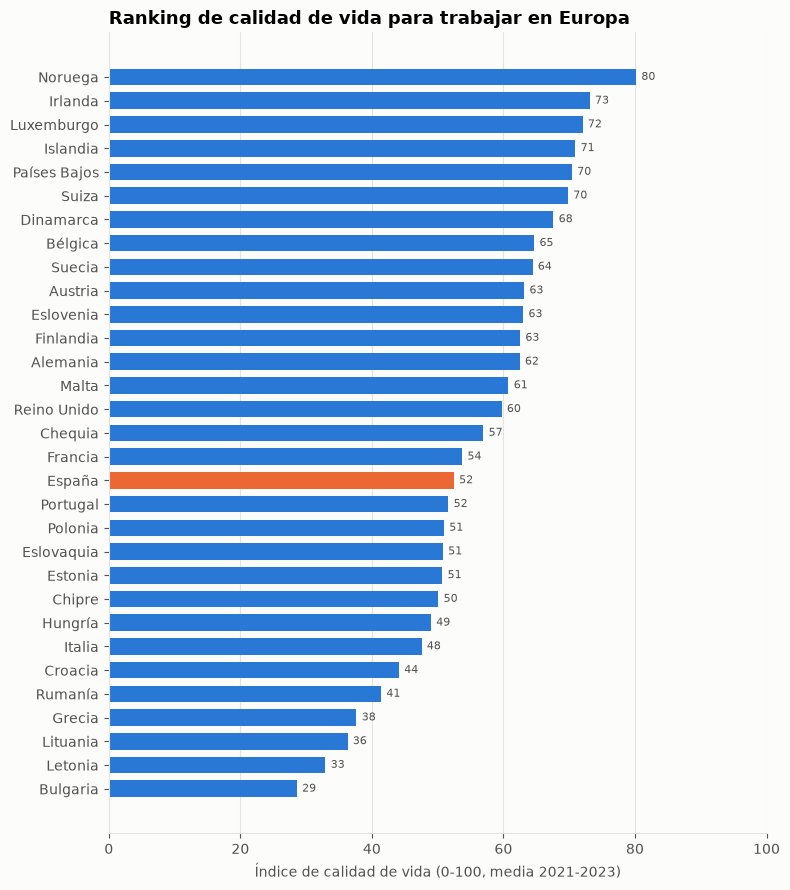

In [22]:
# Estilo de gráficos: fondo claro, ejes y rejilla discretos
AZUL, NARANJA, AGUAMARINA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS_TEXTO, GRIS_SUAVE = "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS_SUAVE, "axes.labelcolor": GRIS_TEXTO,
    "xtick.color": GRIS_TEXTO, "ytick.color": GRIS_TEXTO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRIS_SUAVE, "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10,
})

fig, ax = plt.subplots(figsize=(8, 9))
datos_graf = ranking.sort_values("indice")
colores = [NARANJA if p == "España" else AZUL for p in datos_graf["pais"]]
ax.barh(datos_graf["pais"], datos_graf["indice"], color=colores, height=0.7)
for y, valor in enumerate(datos_graf["indice"]):
    ax.text(valor + 0.8, y, f"{valor:.0f}", va="center", fontsize=8, color=GRIS_TEXTO)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Índice de calidad de vida (0-100, media 2021-2023)")
ax.set_title("Ranking de calidad de vida para trabajar en Europa", loc="left")
plt.tight_layout()
plt.show()

**¿Se vive mejor donde más se gana? Ingresos frente a precios.** El PIB per cápita en PPA ya tiene en cuenta los precios. Aun así, al cruzarlo con el nivel de precios se ve que países con ingresos parecidos pueden tener costes muy distintos para alguien que llega y paga alquiler y consumo a precios locales.

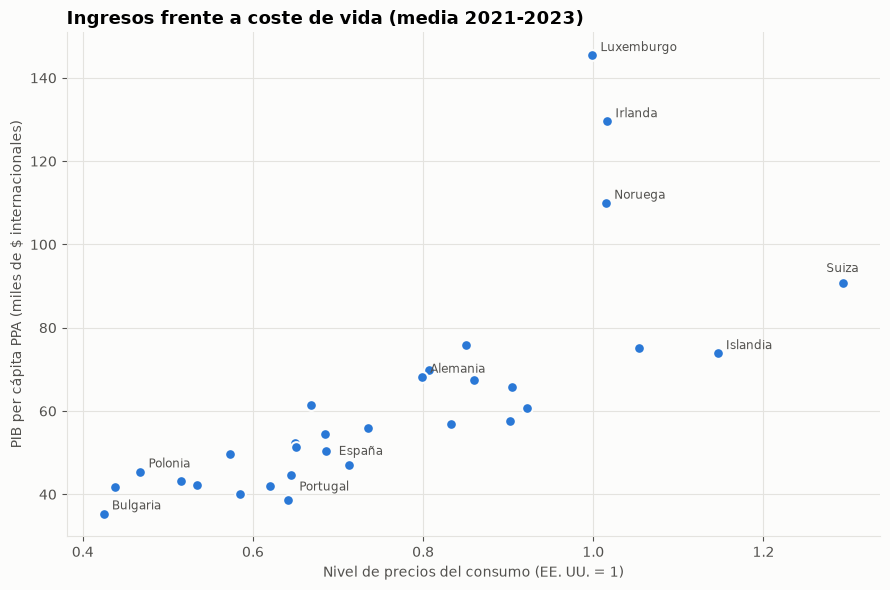

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(reciente["nivel_precios"], reciente["pib_pc_ppa"] / 1000, s=60, color=AZUL,
           edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
# etiquetas solo para algunos países; desplazamiento (x, y) en puntos para que no se pisen
destacar = {"España": (9, -3), "Luxemburgo": (6, 3), "Irlanda": (6, 3), "Suiza": (-12, 8),
            "Bulgaria": (6, 3), "Polonia": (6, 3), "Noruega": (6, 3), "Alemania": (6, 3),
            "Portugal": (6, -11), "Islandia": (6, 3)}
for _, fila in reciente[reciente["pais"].isin(destacar)].iterrows():
    ax.annotate(fila["pais"], (fila["nivel_precios"], fila["pib_pc_ppa"] / 1000),
                xytext=destacar[fila["pais"]], textcoords="offset points",
                fontsize=8.5, color=GRIS_TEXTO)
ax.set_xlabel("Nivel de precios del consumo (EE. UU. = 1)")
ax.set_ylabel("PIB per cápita PPA (miles de $ internacionales)")
ax.set_title("Ingresos frente a coste de vida (media 2021-2023)", loc="left")
plt.tight_layout()
plt.show()

### Comparador de países
La función `comparar_paises` es el núcleo de la idea de negocio. El usuario indica los países que está considerando y obtiene:
- una **tabla** con los valores medios de 2021-2023 y la posición de cada país en el ranking;
- la **evolución del paro desde 2015**, para ver si el mercado laboral va a mejor o a peor.

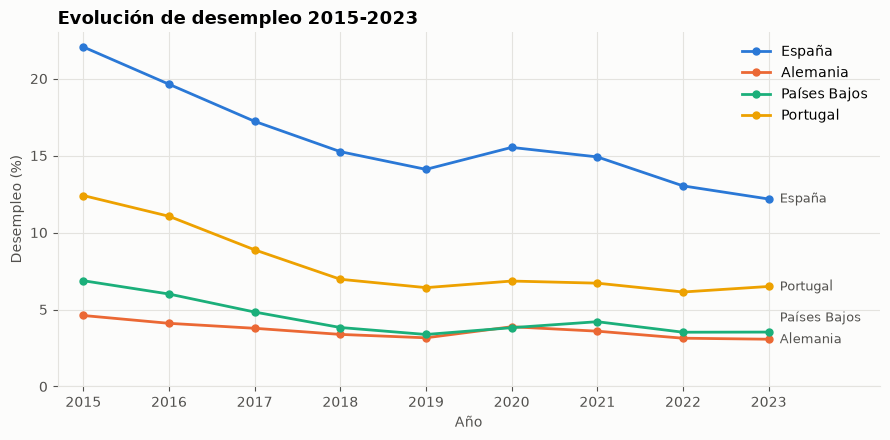

pais,España,Alemania,Países Bajos,Portugal
ranking,18.00,13.00,5.00,19.00
indice,52.48,62.47,70.42,51.63
pib_pc_ppa,50465.17,68187.55,75865.18,44569.34
nivel_precios,0.69,0.80,0.85,0.64
desempleo,13.38,3.27,3.76,6.45
desempleo_juvenil,31.15,6.24,8.42,21.02
inflacion,5.01,5.30,5.51,4.47
esperanza_vida,83.42,80.81,81.60,81.78
gasto_sanitario_pc,3081.36,6424.78,6352.88,2708.96
homicidios,0.66,0.85,0.73,0.74


In [24]:
def comparar_paises(codigos, variable_evolucion="desempleo"):
    # Tabla comparativa (media 2021-2023) y evolución de una variable para 2-4 países.
    if not 2 <= len(codigos) <= 4:
        raise ValueError("Elige entre 2 y 4 países para que el gráfico sea legible.")
    desconocidos = set(codigos) - set(PAISES)
    if desconocidos:
        raise ValueError(f"Códigos no válidos: {desconocidos}. Usa ISO3, p. ej. 'ESP'.")

    columnas = ["ranking", "indice", "pib_pc_ppa", "nivel_precios", "desempleo",
                "desempleo_juvenil", "inflacion", "esperanza_vida", "gasto_sanitario_pc",
                "homicidios", "pm25", "gini", "internet"]
    tabla = reciente.set_index("iso3").loc[codigos].set_index("pais")[columnas].T.round(2)

    colores_serie = [AZUL, NARANJA, AGUAMARINA, AMARILLO]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    etiquetas = []
    for codigo, color in zip(codigos, colores_serie):
        serie = df[df["iso3"] == codigo]
        ax.plot(serie["anio"], serie[variable_evolucion], color=color, linewidth=2,
                marker="o", markersize=5, label=PAISES[codigo])
        etiquetas.append([serie[variable_evolucion].iloc[-1], PAISES[codigo]])
    ax.set_xlim(ANIO_INICIO - 0.3, ANIO_FIN + 1.3)
    ax.set_xticks(range(ANIO_INICIO, ANIO_FIN + 1))
    ax.set_ylim(bottom=0)

    # etiqueta al final de cada línea, separando las que quedarían encima unas de otras
    etiquetas.sort()
    separacion = 0.06 * ax.get_ylim()[1]
    for k in range(1, len(etiquetas)):
        etiquetas[k][0] = max(etiquetas[k][0], etiquetas[k - 1][0] + separacion)
    for y, nombre in etiquetas:
        ax.annotate(nombre, (ANIO_FIN, y), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9, color=GRIS_TEXTO)
    ax.set_xlabel("Año")
    ax.set_ylabel(variable_evolucion.replace("_", " ").capitalize() + " (%)")
    ax.set_title(f"Evolución de {variable_evolucion.replace('_', ' ')} {ANIO_INICIO}-{ANIO_FIN}", loc="left")
    ax.legend(frameon=False, loc="upper right")
    plt.tight_layout()
    plt.show()
    return tabla


# Ejemplo: una persona de España que duda entre quedarse o irse a Alemania, Países Bajos o Portugal
comparar_paises(["ESP", "DEU", "NLD", "PRT"])

In [25]:
# Validación de la entrada: un código mal escrito da un mensaje claro en vez de un KeyError
try:
    comparar_paises(["ESP", "ALE"])
except ValueError as error:
    print("ValueError:", error)

ValueError: Códigos no válidos: {'ALE'}. Usa ISO3, p. ej. 'ESP'.


## 10. Resumen de errores y soluciones

| # | Error | Cómo se manifestó | Causa | Solución |
|---|---|---|---|---|
| 1 | `SSLCertVerificationError` | La primera petición con `requests` falló, aunque el navegador y `curl` sí accedían | `requests` usa su propia lista de certificados (`certifi`) y no confía en la autoridad que firma el tráfico en el equipo | `truststore.inject_into_ssl()` (usa los certificados de Windows), solo si la conexión directa falla. Se descartó `verify=False` por inseguro |
| 2 | `JSONDecodeError` | `respuesta.json()` fallaba | El formato por defecto de la API es **XML** | Añadir siempre `format=json` |
| 3 | Datos incompletos **sin aviso** | Llegaban 50 filas de 279 | La API pagina de 50 en 50 | `per_page=1000` y bucle sobre todas las páginas (`pages`) |
| 4 | Indicador archivado | Código 200, pero el JSON solo traía `message` | `PA.NUS.PPPC.RF` se movió a *WDI Database Archives*; la API no usa los códigos HTTP para estos errores | Excepción propia `ErrorBancoMundial`. El nivel de precios se calcula con `PA.NUS.PRVT.PP / PA.NUS.FCRF` |
| 5 | Tipos incorrectos | El año, la latitud y la longitud llegaban como texto | Así los devuelve la API | Conversión a `int` y `float` |
| 6 | Valores nulos | 13 nulos en homicidios y 15 en Gini | Retrasos en la publicación, encuestas que no son anuales y series casi vacías (Bélgica, Hungría) | Interpolación por país con un límite de 3 años; el resto queda como `NaN` y se marca en `n_imputados` |
| 7 | Monedas mezcladas (**error silencioso**) | Nivel de precios de 0,07 en Croacia y de 0,21 en Bulgaria | La PPA se recalculó en euros para toda la serie, pero el tipo de cambio sigue en kunas o levas antes de la entrada en el euro | Pasar el tipo de cambio a euros con el tipo de conversión fijo oficial (7,53450 HRK/€ y 1,95583 BGN/€) |
| 8 | `ReadTimeout` puntual | Alguna petición tardó más de 60 s | Lentitud ocasional del servidor | Reintentos con espera creciente dentro de `peticion_api`. En la ejecución de desarrollo un indicador falló al primer intento y se recuperó al segundo |

Los errores más peligrosos fueron el **3** y el **7**, porque **no hacen saltar ningún error en Python**. Solo se detectan comprobando los metadatos y revisando si los valores tienen sentido.

## 11. Conclusiones

**Sobre la recogida de datos (el objetivo del entregable)**
- Se ha construido un dataframe de **279 filas (31 países × 9 años) y 20 columnas**, con 6 campos de identificación del país, el año, 11 indicadores descargados y 2 variables calculadas (`nivel_precios` y `n_imputados`). Todo sale de una única fuente gratuita y sin clave, la API del Banco Mundial, consultada a mano con `requests`.
- La parte más costosa no fue descargar los datos, sino **asegurarse de que estaban completos y eran correctos**. Dos de los ocho problemas (la paginación y las monedas mezcladas) no daban ningún error, así que se detectaron revisando los metadatos y comprobando si los valores tenían sentido.
- La función `descargar_indicador` sirve para cualquier otro indicador o país del Banco Mundial cambiando solo el código, así que el comparador se puede ampliar fácilmente.

**Sobre la idea de negocio** (datos consultados en noviembre de 2026, media 2021-2023)
- **Noruega, Irlanda y Luxemburgo** encabezan el índice, seguidos de Islandia, Países Bajos y Suiza. **Bulgaria, Letonia y Lituania** quedan al final.
- **España ocupa el puesto 18 de 31.** Tiene una de las esperanzas de vida más altas (83,4 años) y precios moderados, pero el **paro más alto de los 31 países** (13,4 %, y 31 % entre los jóvenes). Para una persona joven que busca trabajo, ese es el motivo más claro para mirar fuera.
- En el ejemplo del comparador, **Países Bajos** (puesto 5) combina un paro bajo (3,8 %), la menor desigualdad del grupo (Gini 25,7) y un nivel de precios inferior al de Suiza o los países nórdicos. **Alemania** tiene el paro más bajo de los cuatro (3,3 %), y **Portugal** apenas mejora la situación de España.

**Limitaciones**
- El PIB per cápita de **Irlanda y Luxemburgo** está inflado por la sede de multinacionales y por los trabajadores transfronterizos, y no refleja del todo el ingreso de los residentes.
- El índice da el **mismo peso** a todas las dimensiones. Una versión comercial dejaría que cada usuario pusiera sus propios pesos.
- El Banco Mundial no tiene datos **por ciudad** ni de **alquileres o salarios netos**, que son clave para mudarse. Ese sería el siguiente paso, con otra fuente (por ejemplo, la API de Eurostat).